# Used Bike Resale Price Estimation
## Industry-style Data Analysis Project

**Role:** Junior Data Analyst

**Business goal:** Help a used-bike marketplace estimate reasonable listing prices.

**Dataset:** `bikes.csv`

**Workflow:** Data quality audit → cleaning → EDA → feature engineering → Linear Regression → assumption checks → business recommendation.

> **Before running:** Put `bikes.csv` in the same folder as this notebook. This notebook calculates EDA results and model metrics from the data you provide. Do not rely on example numbers before running the cells.

## Q1. Business Data Quality Audit

The marketplace has noticed missing values, inconsistent data types, duplicate listings, and invalid prices. Audit and clean the dataset before analysis.

### Cell 1: Import libraries

In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries loaded.")

Libraries loaded.


### Cell 2: Load and inspect the dataset

In [102]:
df_raw = pd.read_csv("bikes.csv")

print("Dataset shape:", df_raw.shape)
print("\nColumns:")
print(df_raw.columns.tolist())

display(df_raw.head())

Dataset shape: (7857, 8)

Columns:
['model_name', 'model_year', 'kms_driven', 'owner', 'location', 'mileage', 'power', 'price']


,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


### Cell 3: Check data quality

In [103]:
print("Data types:")
print(df_raw.dtypes)

print("\nMissing values:")
print(df_raw.isnull().sum())

print("\nDuplicate rows:", df_raw.duplicated().sum())

if "price" in df_raw.columns:
    print("\nPrice summary:")
    print(df_raw["price"].describe())

Data types:
model_name    object
model_year     int64
kms_driven    object
owner         object
location      object
mileage       object
power         object
price          int64
dtype: object

Missing values:
model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

Duplicate rows: 0

Price summary:
count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64


### Cell 4: Clean numeric columns

In [104]:
df = df_raw.copy()

# Convert common numeric columns to numbers.
# Text such as '35 kmpl' or '25,000 km' will be handled below.
def get_number(value):
    if pd.isna(value):
        return np.nan
    value = str(value).replace(",", "")
    number = ""
    dot_used = False

    for char in value:
        if char.isdigit():
            number += char
        elif char == "." and not dot_used:
            number += char
            dot_used = True
        elif number:
            break

    return float(number) if number else np.nan


for col in ["price", "model_year", "kms_driven", "mileage", "power"]:
    if col in df.columns:
        df[col] = df[col].apply(get_number)

print("Numeric columns converted where possible.")
display(df.head())

Numeric columns converted where possible.


,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,19.80,115000.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,34.50,100000.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00


### Cell 5: Remove duplicates and invalid prices

In [105]:
rows_before = len(df)
duplicates = df.duplicated().sum()
df = df.drop_duplicates()

# Remove rows without a valid positive price.
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]

# Remove impossible model years if the column exists.
if "model_year" in df.columns:
    current_year = pd.Timestamp.today().year
    df = df[df["model_year"].between(1990, current_year)]

# Remove impossible negative values.
for col in ["kms_driven", "mileage", "power"]:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

print("Rows before cleaning:", rows_before)
print("Duplicate rows removed:", duplicates)
print("Rows after basic cleaning:", len(df))
print("Rows removed:", rows_before - len(df))

Rows before cleaning: 7857
Duplicate rows removed: 0
Rows after basic cleaning: 7811
Rows removed: 46


### Cell 6: Create bike age and handle missing values

In [106]:
if "model_year" in df.columns:
    current_year = pd.Timestamp.today().year
    df["bike_age"] = current_year - df["model_year"]

# Keep missing values in numerical predictors for now.
# The model pipeline will impute them after the train/test split.
if "location" in df.columns:
    df["location"] = df["location"].fillna("Unknown")

print("Missing values after basic cleaning:")
print(df.isnull().sum())

Missing values after basic cleaning:
model_name      0
model_year      0
kms_driven      3
owner           0
location        0
mileage       763
power          23
price           0
bike_age        0
dtype: int64


### Cell 7: Save cleaned dataset

In [107]:
df_clean = df.copy()
df_clean.to_csv("bikes_cleaned.csv", index=False)

print("Cleaned dataset saved as bikes_cleaned.csv")
display(df_clean.head())

Cleaned dataset saved as bikes_cleaned.csv


,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00,9.00
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,19.80,115000.00,10.00
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00,14.00
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,34.50,100000.00,9.00
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00,6.00


In [108]:
df_clean['price'].describe()

count      7811.00
mean     107217.97
std      139159.55
min        2000.00
25%       42224.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [109]:
df_clean['price'].skew()

np.float64(6.20981478769428)

<Axes: xlabel='price', ylabel='Count'>

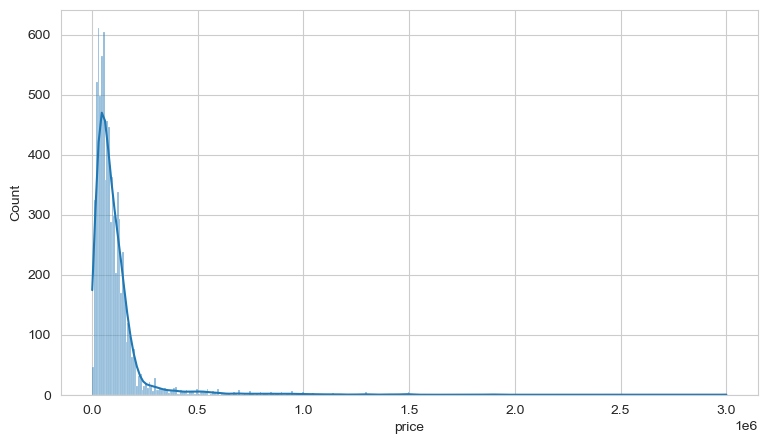

In [110]:
plt.figure(figsize=(9,5))
sns.histplot(data=df_clean,x='price', kde= True)

<Axes: xlabel='price'>

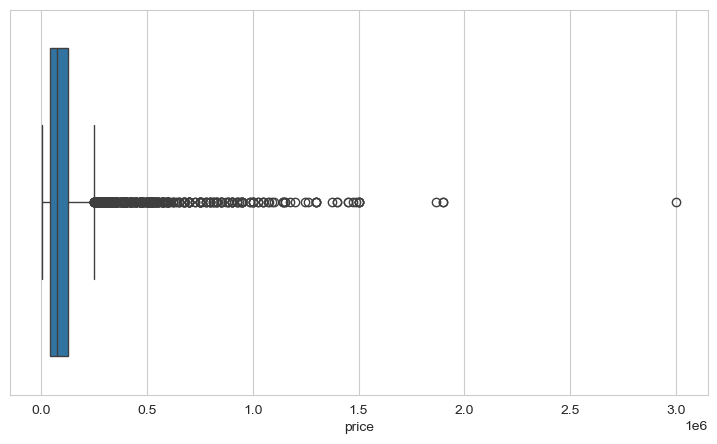

In [111]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df_clean,x='price',)

In [112]:
df_clean['brand']=df_clean['model_name'].str.split().str[0].str.lower()

In [113]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()

In [114]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median', ascending= False).head(10)

<Axes: xlabel='brand', ylabel='median'>

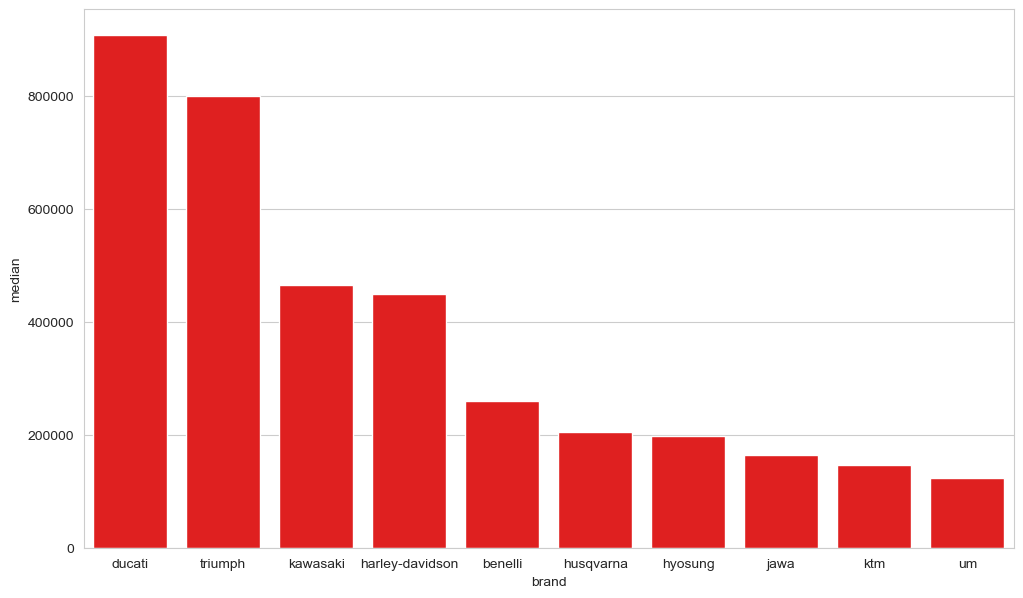

In [115]:
plt.figure(figsize=(12,7))
sns.barplot(data=brand_top_10, x='brand',y='median',color='red')

In [116]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,2017.00,17000.00,first owner,hyderabad,35.00,19.00,63500.00,9.00,bajaj
1,Royal Enfield Classic 350cc 2016,2016.00,50000.00,first owner,hyderabad,35.00,19.80,115000.00,10.00,royal
2,Hyosung GT250R 2012,2012.00,14795.00,first owner,hyderabad,30.00,28.00,300000.00,14.00,hyosung
3,Bajaj Dominar 400 ABS 2017,2017.00,28.00,first owner,pondicherry,28.00,34.50,100000.00,9.00,bajaj
4,Jawa Perak 330cc 2020,2020.00,2000.00,first owner,bangalore,NaN,30.00,197500.00,6.00,jawa
...,...,...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.00,7000.00,first owner,agra,42.00,16.00,55000.00,15.00,yamaha
7853,Bajaj Discover 100cc 2015,2015.00,80.00,first owner,delhi,80.00,7.70,28000.00,11.00,bajaj
7854,Bajaj Pulsar 180cc 2016,2016.00,6407.00,first owner,bangalore,65.00,17.00,61740.00,10.00,bajaj
7855,Bajaj V15 150cc 2016,2016.00,7524.00,first owner,bangalore,57.00,11.80,49000.00,10.00,bajaj


In [117]:
df_clean[['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.00,-0.11
price,-0.11,1.00


<Axes: xlabel='kms_driven', ylabel='price'>

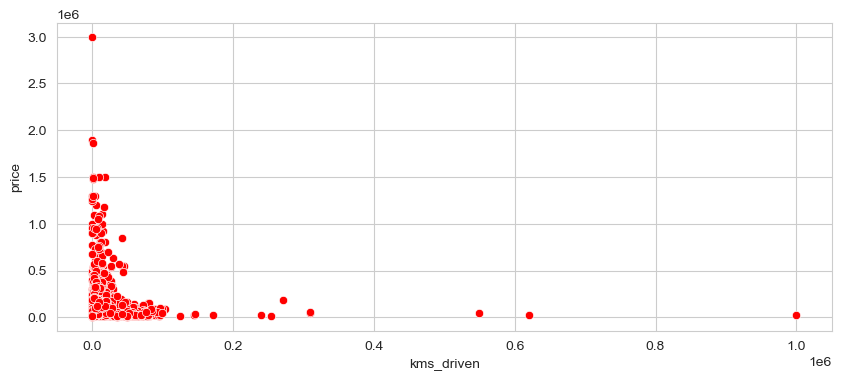

In [118]:

plot_data= df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000, random_state=42)
    
plt.figure(figsize=(10,4))

sns.scatterplot(data= plot_data,x='kms_driven',y='price', color='red')

<Axes: xlabel='kms_driven', ylabel='price'>

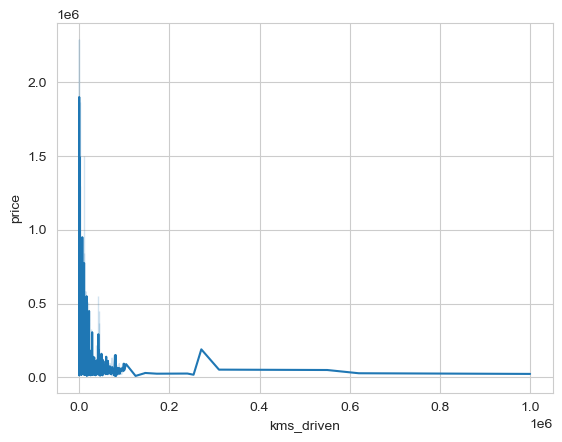

In [119]:
sns.lineplot(data= plot_data,x='kms_driven',y='price')

<Axes: xlabel='bike_age', ylabel='price'>

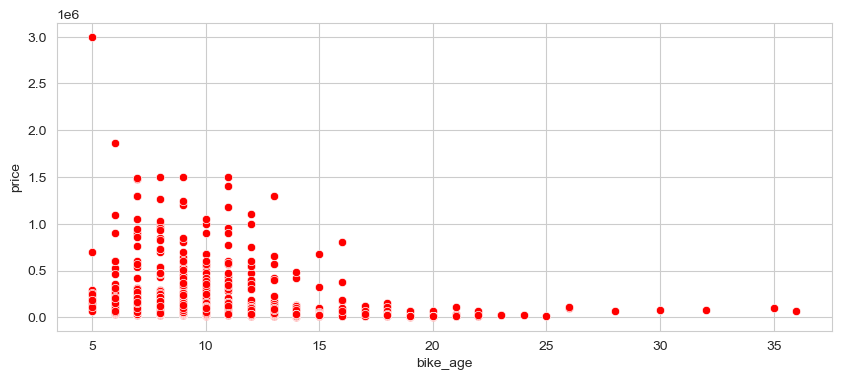

In [120]:

plot_data= df_clean.dropna(subset=['bike_age','price'])
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000, random_state=42)
    
plt.figure(figsize=(10,4))

sns.scatterplot(data= plot_data,x='bike_age',y='price', color='red')

<Axes: >

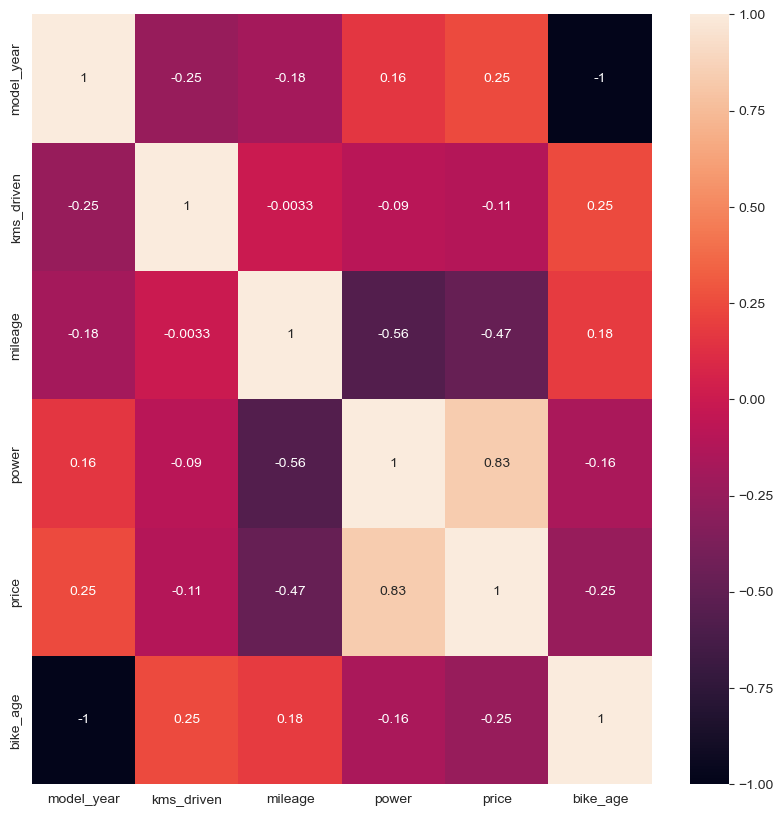

In [121]:
numeric_df= df_clean.select_dtypes(include='number')

plt.figure(figsize=(10,10))
sns.heatmap(numeric_df.corr(), annot= True)


In [122]:
df_clean.dropna(inplace= True)

In [123]:
df_clean.reset_index(inplace=True,drop='first')

In [145]:
data=df_clean.drop(['model_name','location'],axis=1)

In [146]:
data.columns

Index(['model_year', 'kms_driven', 'owner', 'mileage', 'power', 'price',
       'bike_age', 'brand'],
      dtype='object')

In [147]:
x=data[['model_year', 'kms_driven', 'owner', 'mileage', 'power',
       'bike_age', 'brand']]
y= data['price']

In [148]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test= train_test_split(x,y, random_state=42, test_size=0.2)

In [150]:
numerical_column=x.select_dtypes(include='number').columns
categorical_column=x.select_dtypes(exclude='number').columns

In [151]:
numeric_pipeline= Pipeline(steps=[('imputer',SimpleImputer(strategy='median'))])
categorical_pipeline= Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                                 ('ohe', OneHotEncoder(handle_unknown='ignore'))])

In [154]:
transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)
print("Linear Regression model trained.")

Linear Regression model trained.


## Q2. Market Pricing Analysis (EDA)

The sales team wants to understand which bike characteristics may be associated with resale price. All observations below should be written after looking at the output generated by the cells.

### Cell 8: Price statistics

In [125]:
print("Price statistics:")
display(df_clean["price"].describe())

print("Mean price: ₹{:,.0f}".format(df_clean["price"].mean()))
print("Median price: ₹{:,.0f}".format(df_clean["price"].median()))
print("Minimum price: ₹{:,.0f}".format(df_clean["price"].min()))
print("Maximum price: ₹{:,.0f}".format(df_clean["price"].max()))
print("Price skewness:", round(df_clean["price"].skew(), 2))

Price statistics:


count      7041.00
mean     102887.71
std      133134.93
min        2000.00
25%       40000.00
50%       70000.00
75%      120000.00
max     1900000.00
Name: price, dtype: float64

Mean price: ₹102,888
Median price: ₹70,000
Minimum price: ₹2,000
Maximum price: ₹1,900,000
Price skewness: 5.68


### Cell 9: Price distribution and outliers

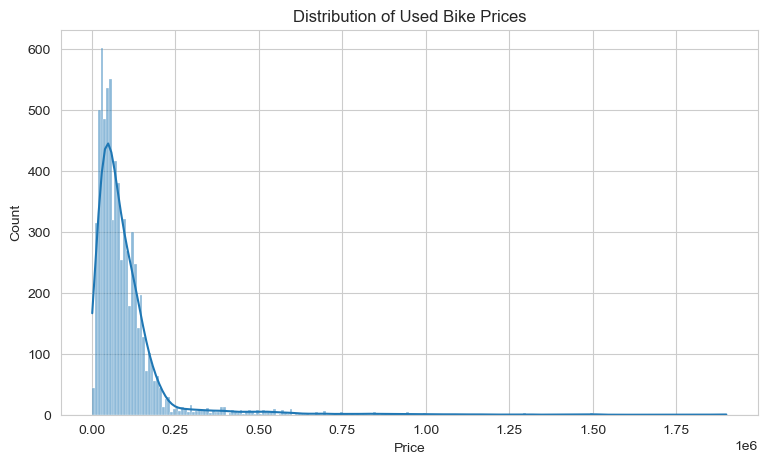

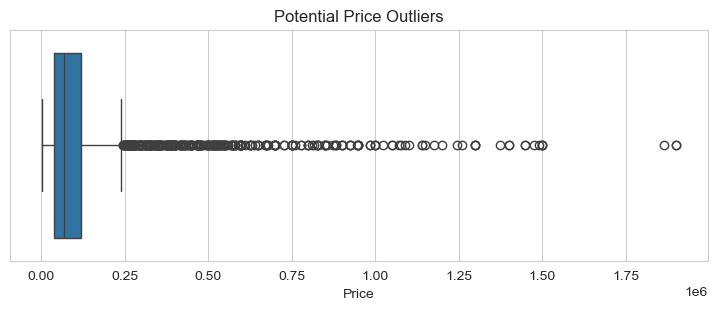

In [126]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="price", kde=True)
plt.title("Distribution of Used Bike Prices")
plt.xlabel("Price")
plt.show()

plt.figure(figsize=(9, 3))
sns.boxplot(data=df_clean, x="price")
plt.title("Potential Price Outliers")
plt.xlabel("Price")
plt.show()

### Cell 10: Brand-level price comparison

,brand,median,mean,count
4,ducati,881875.00,979199.13,15
18,triumph,738125.00,826819.90,30
11,kawasaki,465000.00,499179.78,65
5,harley-davidson,430000.00,493365.74,163
2,benelli,259375.00,305429.81,37
9,hyosung,205000.00,226404.69,49
8,husqvarna,203656.00,205443.70,10
12,ktm,145250.00,148495.21,406
20,um,125000.00,128446.01,128
16,royal,120000.00,121716.99,1633


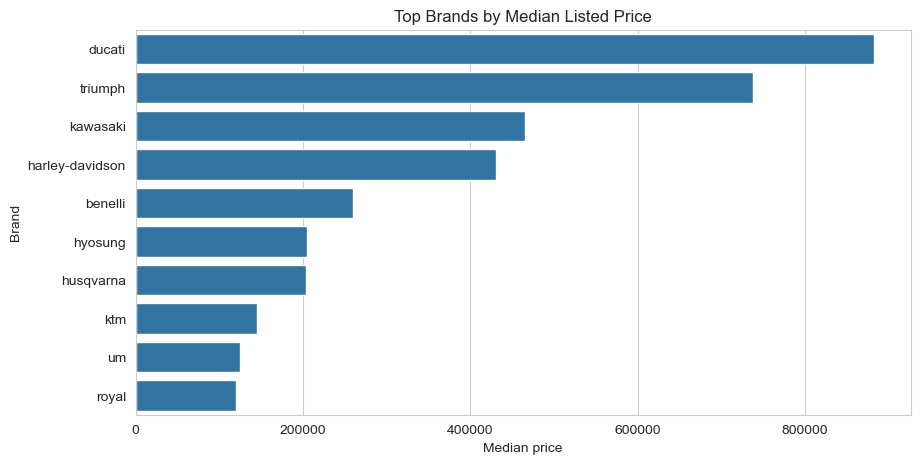

In [127]:
# Extract the first word as a simple brand approximation if brand is not provided.
if "brand" not in df_clean.columns and "model_name" in df_clean.columns:
    df_clean["brand"] = df_clean["model_name"].astype(str).str.split().str[0]

if "brand" in df_clean.columns:
    brand_stats = (
        df_clean.groupby("brand")["price"]
        .agg(["median", "mean", "count"])
        .reset_index()
    )

    # Avoid comparing brands represented by only a few listings.
    brand_stats = brand_stats[brand_stats["count"] >= 10]
    brand_stats = brand_stats.sort_values("median", ascending=False)

    display(brand_stats.head(10))

    top_brands = brand_stats.head(10)
    plt.figure(figsize=(10, 5))
    sns.barplot(data=top_brands, x="median", y="brand")
    plt.title("Top Brands by Median Listed Price")
    plt.xlabel("Median price")
    plt.ylabel("Brand")
    plt.show()
else:
    print("Brand analysis skipped: model_name/brand column not found.")

### Cell 11: Kilometres driven versus price

Correlation between kilometres and price: -0.108


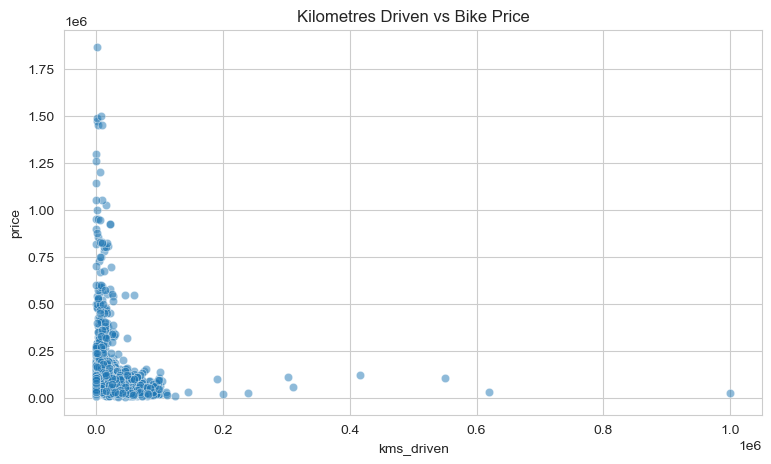

In [128]:
if "kms_driven" in df_clean.columns:
    print(
        "Correlation between kilometres and price:",
        round(df_clean[["kms_driven", "price"]].corr().iloc[0, 1], 3)
    )

    plot_data = df_clean.dropna(subset=["kms_driven", "price"])
    if len(plot_data) > 3000:
        plot_data = plot_data.sample(3000, random_state=42)

    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=plot_data, x="kms_driven", y="price", alpha=0.5)
    plt.title("Kilometres Driven vs Bike Price")
    plt.show()

### Cell 12: Bike age versus price

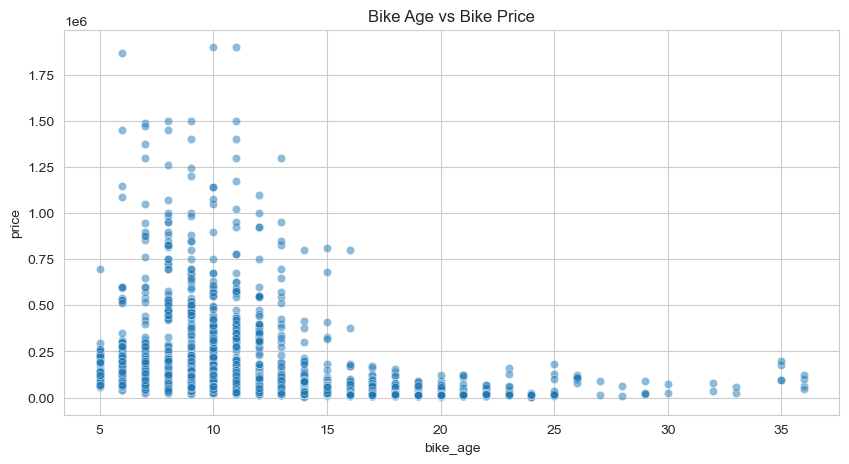

Correlation between bike age and price: -0.252


In [129]:
if "bike_age" in df_clean.columns:
    plot_data = df_clean.dropna(subset=["bike_age", "price"])
    plot_data = plot_data[plot_data["bike_age"].between(0, 40)]

    plt.figure(figsize=(10, 5))
    sns.scatterplot(data=plot_data, x="bike_age", y="price", alpha=0.5)
    plt.title("Bike Age vs Bike Price")
    plt.show()

    print(
        "Correlation between bike age and price:",
        round(df_clean[["bike_age", "price"]].corr().iloc[0, 1], 3)
    )

### Cell 13: Correlation heatmap

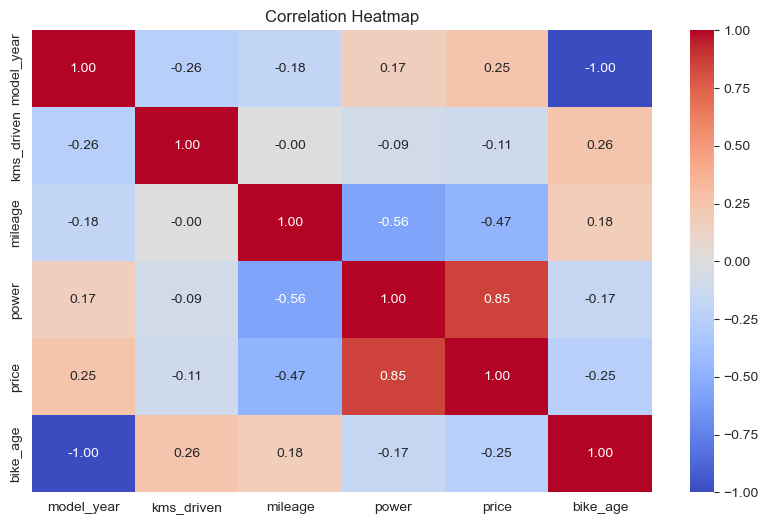

Correlation of numeric features with price:
price         1.00
power         0.85
model_year    0.25
kms_driven   -0.11
bike_age     -0.25
mileage      -0.47
Name: price, dtype: float64


In [130]:
numeric_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print("Correlation of numeric features with price:")
print(numeric_df.corr()["price"].sort_values(ascending=False))

### Cell 14: Investigate high-price outliers

In [131]:
q1 = df_clean["price"].quantile(0.25)
q3 = df_clean["price"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

high_price_bikes = df_clean[df_clean["price"] > upper_limit]

print("IQR upper limit: ₹{:,.0f}".format(upper_limit))
print("Number of high-price records:", len(high_price_bikes))

cols_to_show = [c for c in ["model_name", "brand", "model_year", "power", "price"] if c in df_clean.columns]
display(high_price_bikes[cols_to_show].head(15))

IQR upper limit: ₹240,000
Number of high-price records: 361


,model_name,brand,model_year,power,price
2,Hyosung GT250R 2012,hyosung,2012.00,28.00,300000.00
134,TVS Apache RR310 BS6 2020,tvs,2020.00,33.00,263000.00
144,KTM RC 390cc 2020,ktm,2020.00,42.30,290000.00
170,TVS Apache RR310 BS6 2021,tvs,2021.00,33.00,249000.00
346,Bajaj Avenger Street 150 2016,bajaj,2016.00,14.30,550000.00
420,Harley-Davidson Street Bob 2013,harley-davidson,2013.00,65.00,545000.00
556,TVS Apache RR310 BS6 2020,tvs,2020.00,33.00,260000.00
595,Royal Enfield Continental GT 535cc 2018,royal,2018.00,29.10,275000.00
1113,Kawasaki Z1000 2019,kawasaki,2019.00,139.00,760000.00
1205,KTM Duke 390cc BS6 2020,ktm,2020.00,42.90,265000.00


### EDA findings to write

After running the EDA cells, write evidence-based observations about:
- Price distribution, typical price range, and skewness.
- Brands with higher median listing prices.
- Relationship between kilometres driven and price.
- Relationship between bike age and price.
- Numeric features most strongly correlated with price.
- High-price outliers and whether they appear to be valid premium listings.

## Q3. Feature Engineering and Variable Selection

Choose features based on EDA and business understanding. Do not include both `model_year` and `bike_age` in the same model because they contain essentially the same information.

### Prepare model features

In [132]:
# Use only columns that actually exist in this dataset.
numeric_candidates = ["bike_age", "kms_driven", "power", "mileage"]
categorical_candidates = ["owner", "brand", "location"]

numeric_features = [c for c in numeric_candidates if c in df_clean.columns]
categorical_features = [c for c in categorical_candidates if c in df_clean.columns]

features = numeric_features + categorical_features

if not features:
    raise ValueError("No usable predictor columns found. Check the dataset columns.")

df_model = df_clean[features + ["price"]].copy()
X = df_model[features]
y = df_model["price"]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Model dataset shape:", df_model.shape)

Numeric features: ['bike_age', 'kms_driven', 'power', 'mileage']
Categorical features: ['owner', 'brand', 'location']
Model dataset shape: (7041, 8)


### Check numerical relationships and correlations

In [133]:
numeric_for_corr = [c for c in numeric_features if c in df_model.columns]

if numeric_for_corr:
    display(df_model[numeric_for_corr + ["price"]].corr())

    print("Feature correlation with price:")
    print(df_model[numeric_for_corr + ["price"]].corr()["price"].sort_values())

,bike_age,kms_driven,power,mileage,price
bike_age,1.00,0.26,-0.17,0.18,-0.25
kms_driven,0.26,1.00,-0.09,-0.00,-0.11
power,-0.17,-0.09,1.00,-0.56,0.85
mileage,0.18,-0.00,-0.56,1.00,-0.47
price,-0.25,-0.11,0.85,-0.47,1.00


Feature correlation with price:
mileage      -0.47
bike_age     -0.25
kms_driven   -0.11
power         0.85
price         1.00
Name: price, dtype: float64


## Q4. Build a Bike Price Estimation Model

We will use an 80/20 train-test split. Imputation and one-hot encoding are fitted on the training data through a pipeline to reduce data leakage.

### Cell 17: Train-test split

In [134]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 5632
Testing rows: 1409


### Cell 18: Build preprocessing and Linear Regression pipeline

In [135]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipeline, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regression", LinearRegression())
])

model.fit(X_train, y_train)
print("Linear Regression model trained.")

Linear Regression model trained.


### Cell 19: Predict and compare actual prices

In [136]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "actual_price": y_test.values,
    "predicted_price": np.round(y_pred, 0),
    "error_actual_minus_predicted": np.round(y_test.values - y_pred, 0)
})
comparison["absolute_error"] = comparison["error_actual_minus_predicted"].abs()

display(comparison.head(15))

,actual_price,predicted_price,error_actual_minus_predicted,absolute_error
0,32250.00,20268.00,11982.00,11982.00
1,129000.00,104675.00,24325.00,24325.00
2,210000.00,137185.00,72815.00,72815.00
3,181562.00,142696.00,38866.00,38866.00
4,259375.00,279474.00,-20099.00,20099.00
5,20000.00,49075.00,-29075.00,29075.00
6,70000.00,54184.00,15816.00,15816.00
7,95000.00,181255.00,-86255.00,86255.00
8,38000.00,19484.00,18516.00,18516.00
9,135000.00,136596.00,-1596.00,1596.00


## Q5. Model Validation and Business Recommendation

### Cell 20: Calculate model evaluation metrics

In [137]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE: ₹{:,.0f}".format(mae))
print("MSE: {:,.0f}".format(mse))
print("RMSE: ₹{:,.0f}".format(rmse))
print("R²: {:.3f}".format(r2))

MAE: ₹30,699
MSE: 4,865,168,852
RMSE: ₹69,751
R²: 0.751


### Cell 21: Actual versus predicted prices

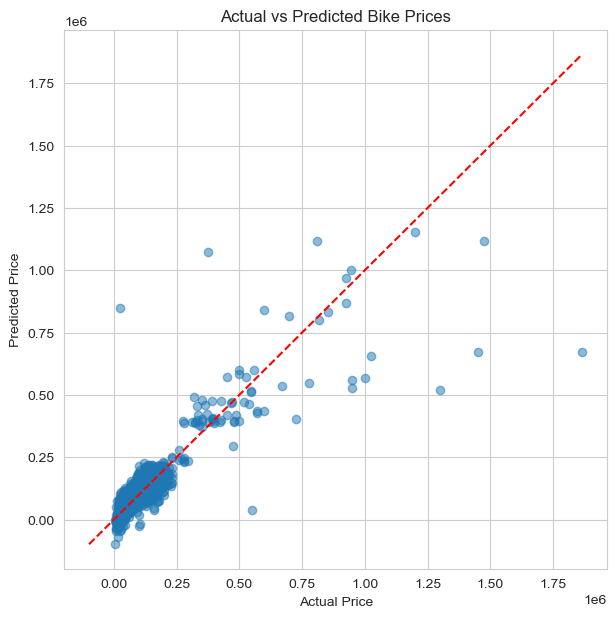

In [138]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.5)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Bike Prices")
plt.show()

### Cell 22: Residual analysis

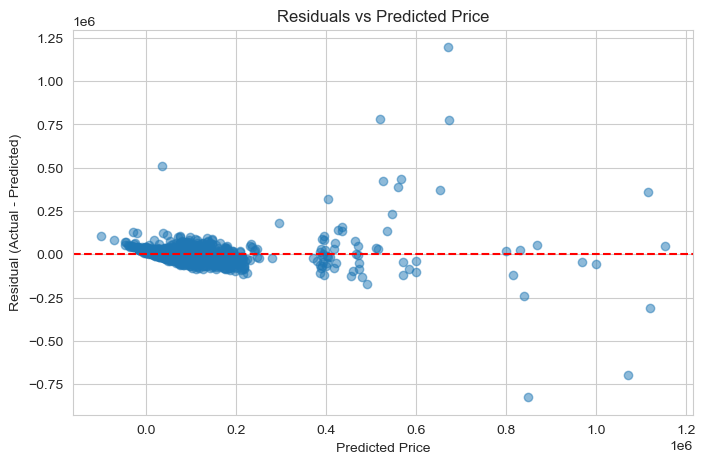

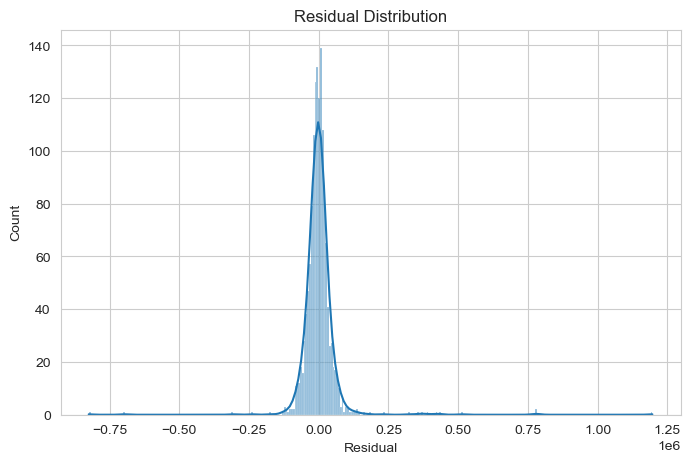

Mean residual: 608.71


In [139]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted Price")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.show()

print("Mean residual:", round(residuals.mean(), 2))

### Cell 23: Check residual normality and changing variance

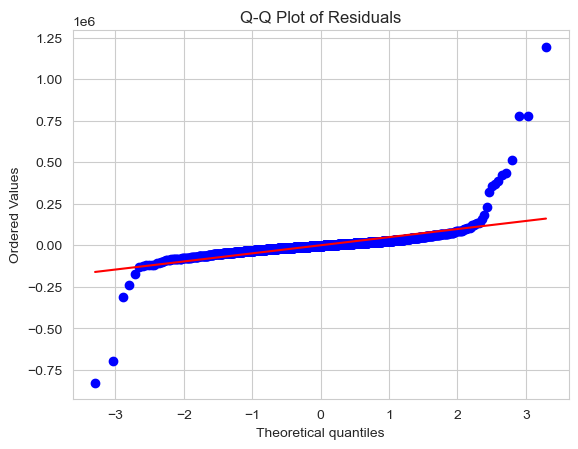

Correlation: predicted price vs absolute residual: 0.355
p-value: 0.0


In [140]:
# Q-Q plot: points near the line suggest residuals are closer to normal.
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

# A correlation between predicted price and absolute residuals can indicate
# that error size changes with predicted price. This is a diagnostic, not a formal test.
from scipy.stats import spearmanr

corr, p_value = spearmanr(y_pred, np.abs(residuals))
print("Correlation: predicted price vs absolute residual:", round(corr, 3))
print("p-value:", round(p_value, 5))

### Cell 24: Largest prediction errors

In [141]:
comparison["percentage_error"] = (
    comparison["error_actual_minus_predicted"] / comparison["actual_price"] * 100
)

print("Largest underestimates (actual price is higher than prediction):")
display(comparison.nlargest(5, "error_actual_minus_predicted"))

print("Largest overestimates (prediction is higher than actual price):")
display(comparison.nsmallest(5, "error_actual_minus_predicted"))

Largest underestimates (actual price is higher than prediction):


,actual_price,predicted_price,error_actual_minus_predicted,absolute_error,percentage_error
834,1866057.00,670015.00,1196042.00,1196042.00,64.09
368,1299999.00,519805.00,780194.00,780194.00,60.01
1271,1450000.00,673659.00,776341.00,776341.00,53.54
852,550000.00,37362.00,512638.00,512638.00,93.21
611,1000000.00,567732.00,432268.00,432268.00,43.23


Largest overestimates (prediction is higher than actual price):


,actual_price,predicted_price,error_actual_minus_predicted,absolute_error,percentage_error
338,23000.00,847921.00,-824921.00,824921.00,-3586.61
218,375000.00,1071260.00,-696260.00,696260.00,-185.67
1268,810000.00,1118235.00,-308235.00,308235.00,-38.05
455,600000.00,839341.00,-239341.00,239341.00,-39.89
78,320000.00,492090.00,-172090.00,172090.00,-53.78


### Cell 25: Save outputs

In [142]:
comparison.to_csv("bike_price_predictions.csv", index=False)

import joblib
joblib.dump(model, "bike_price_linear_regression.joblib")

print("Saved bike_price_predictions.csv")
print("Saved bike_price_linear_regression.joblib")

Saved bike_price_predictions.csv
Saved bike_price_linear_regression.joblib


## Final Business Recommendation

Use the model as a suggested listing-price assistant, not as an automatic price setter. Review the test-set MAE and RMSE, inspect residual plots, and pay particular attention to premium bikes where errors may be larger.

---

© 2026 Raj Digital Pvt. Ltd. All Rights Reserved.